<a href="https://colab.research.google.com/github/AnjanaVP231/ML/blob/main/lab2NaiveBayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Naive_Bayes_Dataset.xlsx - Naive_Bayes_Dataset.csv to Naive_Bayes_Dataset.xlsx - Naive_Bayes_Dataset (6).csv
First 10 records:
   Study_Hours_Per_Day  Attendance_Percent  Assignment_Score_Percent  \
0                    1                  92                        67   
1                    7                  85                        79   
2                    6                  70                        78   
3                    4                  94                        69   
4                    4                  71                        88   
5                    7                  68                        73   
6                    1                  92                        49   
7                    6                  70                        84   
8                    2                  58                        74   
9                    1                  74                        77   

   Previous_Marks_Percent Study_Level Attendance_Level Assignment_Level R

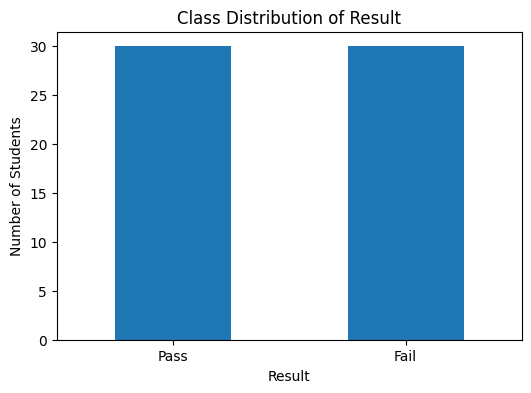


Numerical features:
['Study_Hours_Per_Day', 'Attendance_Percent', 'Assignment_Score_Percent', 'Previous_Marks_Percent']

Categorical features:
['Study_Level', 'Attendance_Level', 'Assignment_Level']

TASK 2

Prior Probability:
P(Pass) = 0.5
P(Fail) = 0.5

New Student:
{'Study_Level': 'High', 'Attendance_Level': 'High', 'Assignment_Level': 'High'}

Conditional Probabilities:
Study_Level = High
P(value | Pass) = 0.6
P(value | Fail) = 0.3
Attendance_Level = High
P(value | Pass) = 0.36666666666666664
P(value | Fail) = 0.23333333333333334
Assignment_Level = High
P(value | Pass) = 0.36666666666666664
P(value | Fail) = 0.2

Likelihood:
P(X | Pass) = 0.08066666666666665
P(X | Fail) = 0.013999999999999999

Posterior:
P(Pass | X) proportional to 0.040333333333333325
P(Fail | X) proportional to 0.006999999999999999

Normalized Posterior:
P(Pass | X) = 0.852112676056338
P(Fail | X) = 0.147887323943662

Prediction: Pass

TASK 3

Zero-frequency situation:
P(Very High | Pass) = 0.0
P(Very High | Fai

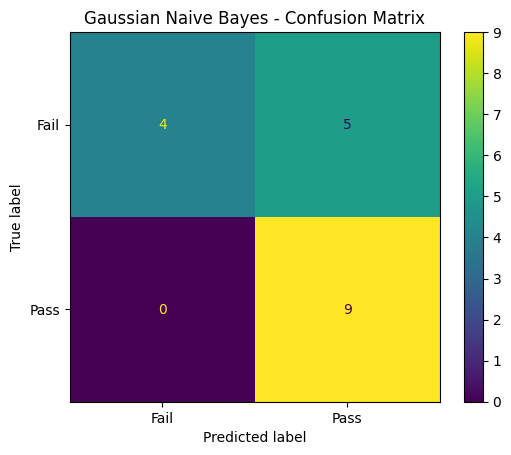


Accuracy : 0.7222222222222222
Precision: 0.8214285714285715
Recall   : 0.7222222222222222
F1-score : 0.6989966555183946

TASK 5

Categorical Naive Bayes:
Accuracy : 0.6111111111111112
Precision: 0.6607142857142857
Recall   : 0.6111111111111112
F1-score : 0.5785953177257525

Comparison with Gaussian Naive Bayes:
      Metric  GaussianNB  CategoricalNB
0   Accuracy    0.722222       0.611111
1  Precision    0.821429       0.660714
2     Recall    0.722222       0.611111
3   F1-score    0.698997       0.578595

TASK 6

New Student Predictions:

Student 1
Predicted Class: Pass
P(Fail) = 0.02941280470869681
P(Pass) = 0.9705871952913039

Student 2
Predicted Class: Fail
P(Fail) = 0.9765910822048469
P(Pass) = 0.023408917795152515

Student 3
Predicted Class: Pass
P(Fail) = 0.16204183757192797
P(Pass) = 0.8379581624280712


In [ ]:
# ============================================================
# LAB 2 - NAIVE BAYES CLASSIFICATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# TASK 1 - LOAD AND UNDERSTAND THE DATASET
# ============================================================

uploaded = files.upload()
file = list(uploaded.keys())[0]

df = pd.read_csv(file)

print("First 10 records:")
print(df.head(10))

target = "Result"

X = df.drop(columns=target)
y = df[target]

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(target)

print("\nClass distribution:")
print(y.value_counts())

plt.figure(figsize=(6, 4))
y.value_counts().plot(kind="bar")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.title("Class Distribution of Result")
plt.xticks(rotation=0)
plt.show()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)


# ============================================================
# TASK 2 - BAYES THEOREM AND PROBABILITY CALCULATION
# ============================================================

print("\n" + "=" * 50)
print("TASK 2")
print("=" * 50)

# Prior probabilities
pass_count = (df["Result"] == "Pass").sum()
fail_count = (df["Result"] == "Fail").sum()

P_pass = pass_count / len(df)
P_fail = fail_count / len(df)

print("\nPrior Probability:")
print("P(Pass) =", P_pass)
print("P(Fail) =", P_fail)

# Selected categorical features
features = [
    "Study_Level",
    "Attendance_Level",
    "Assignment_Level"
]

# New student
new_student = {
    "Study_Level": "High",
    "Attendance_Level": "High",
    "Assignment_Level": "High"
}

print("\nNew Student:")
print(new_student)

pass_conditional = []
fail_conditional = []

print("\nConditional Probabilities:")

for feature in features:

    value = new_student[feature]

    pass_probability = (
        ((df[feature] == value) &
         (df["Result"] == "Pass")).sum()
        / pass_count
    )

    fail_probability = (
        ((df[feature] == value) &
         (df["Result"] == "Fail")).sum()
        / fail_count
    )

    pass_conditional.append(pass_probability)
    fail_conditional.append(fail_probability)

    print(feature, "=", value)
    print("P(value | Pass) =", pass_probability)
    print("P(value | Fail) =", fail_probability)

# Conditional independence:
# Multiply individual conditional probabilities
pass_likelihood = np.prod(pass_conditional)
fail_likelihood = np.prod(fail_conditional)

print("\nLikelihood:")
print("P(X | Pass) =", pass_likelihood)
print("P(X | Fail) =", fail_likelihood)

# Posterior
pass_posterior = pass_likelihood * P_pass
fail_posterior = fail_likelihood * P_fail

print("\nPosterior:")
print("P(Pass | X) proportional to", pass_posterior)
print("P(Fail | X) proportional to", fail_posterior)

# Normalize
total = pass_posterior + fail_posterior

normalized_pass = pass_posterior / total
normalized_fail = fail_posterior / total

print("\nNormalized Posterior:")
print("P(Pass | X) =", normalized_pass)
print("P(Fail | X) =", normalized_fail)

prediction = (
    "Pass"
    if normalized_pass > normalized_fail
    else "Fail"
)

print("\nPrediction:", prediction)


# ============================================================
# TASK 3 - LAPLACE SMOOTHING AND COMPLETE WORKING
# ============================================================

print("\n" + "=" * 50)
print("TASK 3")
print("=" * 50)

# Demonstrate zero-frequency situation
# "Very High" does not occur in the dataset

unseen_value = "Very High"

zero_pass = (
    (df["Study_Level"] == unseen_value) &
    (df["Result"] == "Pass")
).sum()

zero_fail = (
    (df["Study_Level"] == unseen_value) &
    (df["Result"] == "Fail")
).sum()

print("\nZero-frequency situation:")
print("P(Very High | Pass) =", zero_pass / pass_count)
print("P(Very High | Fail) =", zero_fail / fail_count)

# Laplace smoothing
k = df["Study_Level"].nunique() + 1

laplace_pass = (zero_pass + 1) / (pass_count + k)
laplace_fail = (zero_fail + 1) / (fail_count + k)

print("\nAfter Laplace smoothing:")
print("P(Very High | Pass) =", laplace_pass)
print("P(Very High | Fail) =", laplace_fail)


# Complete Naive Bayes calculation using Laplace smoothing

smooth_pass = []
smooth_fail = []

for feature in features:

    value = new_student[feature]

    pass_frequency = (
        (df[feature] == value) &
        (df["Result"] == "Pass")
    ).sum()

    fail_frequency = (
        (df[feature] == value) &
        (df["Result"] == "Fail")
    ).sum()

    categories = df[feature].nunique()

    pass_probability = (
        (pass_frequency + 1)
        / (pass_count + categories)
    )

    fail_probability = (
        (fail_frequency + 1)
        / (fail_count + categories)
    )

    smooth_pass.append(pass_probability)
    smooth_fail.append(fail_probability)


# Probability table
probability_table = pd.DataFrame({
    "Feature": features,
    "Value": [new_student[f] for f in features],
    "P(Value | Pass)": smooth_pass,
    "P(Value | Fail)": smooth_fail
})

print("\nProbability Table:")
print(probability_table)


# Likelihood
smooth_pass_likelihood = np.prod(smooth_pass)
smooth_fail_likelihood = np.prod(smooth_fail)

# Posterior
smooth_pass_posterior = (
    smooth_pass_likelihood * P_pass
)

smooth_fail_posterior = (
    smooth_fail_likelihood * P_fail
)

# Normalize
smooth_total = (
    smooth_pass_posterior +
    smooth_fail_posterior
)

smooth_normalized_pass = (
    smooth_pass_posterior / smooth_total
)

smooth_normalized_fail = (
    smooth_fail_posterior / smooth_total
)

print("\nComplete Calculation:")

print("\nPrior:")
print("P(Pass) =", P_pass)
print("P(Fail) =", P_fail)

print("\nLikelihood:")
print("P(X | Pass) =", smooth_pass_likelihood)
print("P(X | Fail) =", smooth_fail_likelihood)

print("\nPosterior:")
print("P(Pass | X) =", smooth_pass_posterior)
print("P(Fail | X) =", smooth_fail_posterior)

print("\nNormalized Posterior:")
print("P(Pass | X) =", smooth_normalized_pass)
print("P(Fail | X) =", smooth_normalized_fail)

smooth_prediction = (
    "Pass"
    if smooth_normalized_pass > smooth_normalized_fail
    else "Fail"
)

print("\nPrediction:", smooth_prediction)


# ============================================================
# TASK 4 - GAUSSIAN NAIVE BAYES
# ============================================================

print("\n" + "=" * 50)
print("TASK 4")
print("=" * 50)

X_num = df[numerical_features]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X_num,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

gaussian_nb = GaussianNB()

gaussian_nb.fit(X_train, y_train)

y_pred = gaussian_nb.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot()
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.show()

# Metrics
gaussian_accuracy = accuracy_score(y_test, y_pred)

gaussian_precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

gaussian_recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

gaussian_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("\nAccuracy :", gaussian_accuracy)
print("Precision:", gaussian_precision)
print("Recall   :", gaussian_recall)
print("F1-score :", gaussian_f1)


# ============================================================
# TASK 5 - CATEGORICAL NAIVE BAYES
# ============================================================

print("\n" + "=" * 50)
print("TASK 5")
print("=" * 50)

# Encode categorical features
X_cat = pd.DataFrame()

for feature in categorical_features:
    encoder = LabelEncoder()
    X_cat[feature] = encoder.fit_transform(df[feature])

X_cat_train, X_cat_test, y_cat_train, y_cat_test = train_test_split(
    X_cat,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

categorical_nb = CategoricalNB()

categorical_nb.fit(
    X_cat_train,
    y_cat_train
)

y_cat_pred = categorical_nb.predict(X_cat_test)

categorical_accuracy = accuracy_score(
    y_cat_test,
    y_cat_pred
)

categorical_precision = precision_score(
    y_cat_test,
    y_cat_pred,
    average="weighted"
)

categorical_recall = recall_score(
    y_cat_test,
    y_cat_pred,
    average="weighted"
)

categorical_f1 = f1_score(
    y_cat_test,
    y_cat_pred,
    average="weighted"
)

print("\nCategorical Naive Bayes:")
print("Accuracy :", categorical_accuracy)
print("Precision:", categorical_precision)
print("Recall   :", categorical_recall)
print("F1-score :", categorical_f1)

print("\nComparison with Gaussian Naive Bayes:")

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "GaussianNB": [
        gaussian_accuracy,
        gaussian_precision,
        gaussian_recall,
        gaussian_f1
    ],
    "CategoricalNB": [
        categorical_accuracy,
        categorical_precision,
        categorical_recall,
        categorical_f1
    ]
})

print(comparison)


# ============================================================
# TASK 6 - NEW PREDICTION
# ============================================================

print("\n" + "=" * 50)
print("TASK 6")
print("=" * 50)

new_students = pd.DataFrame({
    "Study_Hours_Per_Day": [7, 3, 6],
    "Attendance_Percent": [90, 60, 80],
    "Assignment_Score_Percent": [85, 50, 75],
    "Previous_Marks_Percent": [80, 45, 70]
})

new_predictions = gaussian_nb.predict(new_students)

new_probabilities = gaussian_nb.predict_proba(new_students)

predicted_classes = label_encoder.inverse_transform(
    new_predictions
)

print("\nNew Student Predictions:")

for i in range(3):

    print("\nStudent", i + 1)
    print("Predicted Class:", predicted_classes[i])

    for j, class_name in enumerate(
        label_encoder.classes_
    ):
        print(
            "P(" + class_name + ") =",
            new_probabilities[i][j]
        )